# 02 Deforest: forest conversion on the Rondonia deforestation front, 2019 to 2022

This notebook walks through the `deforest` app of `tessera_apps` on its bundled demo: a 20 km x 20 km box in
Rondonia, Brazil, centred on 8.67 S, 63.11 W, about 87 km east of Porto Velho. The box sits on an active
deforestation front: Hansen Global Forest Change records stand-replacing loss on about 22% of it between 2020 and
2022 (survey S14 moved the demo here from a box on the city itself, which has 1.4%). It lies in one UTM zone
group of the store, 20S.

Everything here runs on the TESSERA v1.1 annual embeddings: one 128-dimensional int8 vector per 10 m pixel per
year, read anonymously from the public Icechunk store. No GPU, no credentials. The only model trained is a
logistic regression with 128 weights.

Section 9 is the one to read if you work where no forest map exists: it runs the app on labels you supply
yourself, shows how many you need, and exports a template of points to label.

## 1. What the app answers

**Where did forest become something else between two years, and what is the forest baseline now?**

The method:

1. **Labels for `year_a`.** By default they come from Hansen GFC (version GFC-2025-v1.13), sampled in a ring
   0 to 5 km *around* the AOI, never inside it, so the comparison with Hansen inside the AOI is spatially held
   out. Forest is `treecover2000 >= 50` with no loss through `year_a`; non-forest is `treecover2000 < 10`, or
   loss at least two years before `year_a` (so it reads as cleared by then). Pixels between the two cover cuts,
   and pixels lost in `year_a - 1` or `year_a`, are not labels. Tree cover is not forest (plantations count,
   forest grown since 2000 does not), and both cuts are choices. Sampling is clustered to cap the cost: up to
   24 store chunks of the ring, then up to 500 pixels per class from those chunks, read once per chunk.
   `--labels path.csv` replaces all of this with your own points (section 9).
2. **Classifier.** Standardized dequantized vectors, then logistic regression (balanced class weights). Its
   skill is estimated on held-out store chunks (group k-fold, 5 folds), so no chunk is in both the training and
   the test part of a fold.
3. **Predict.** Forest probability for every AOI pixel in `year_a` and `year_b`, streamed block by block.
   Forest is `p >= 0.5`. Pixels whose radar regime (Sentinel-1 present or not) differs between the years are not
   classified (survey B5); there are none here.
4. **Conversion.** Forest in `year_a`, non-forest in `year_b`, *and* a cosine distance between the two years'
   embeddings above a cross-check cut: the 95th percentile of the distance among pixels classed forest in both
   years (survey N13; the brief's "above the AOI median" would pass half of all pixels by definition). Then a
   3 x 3 opening and patches of at least 0.5 ha.
5. **Validate.** Against Hansen loss after `year_a` through `year_b` (lossyear 2020 to 2022 here), on Hansen land
   pixels, plus the brief's narrower comparison with loss in `year_b` only, and the agreement of each year's
   forest map with Hansen's forest proxy.

Outputs: a float32 COG with four bands (`forest_prob_2019`, `forest_prob_2022`, `distance_2019_2022`,
`converted`), a summary table (parquet and csv), the training labels (parquet), a preview PNG, a validation JSON
and a report JSON with provenance, timings and bytes read.

In [1]:
from __future__ import annotations

import json
import logging
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.plot import plotting_extent
from scipy import ndimage
from shapely.geometry import Polygon
from sklearn.cluster import KMeans

import tessera_apps
from tessera_apps import io, metrics, validate
from tessera_apps.apps import AppInputError, deforest, load_aoi, run_deforest

# Show the app's own log lines (the run plan, "outputs are current", bytes read).
_handler = logging.StreamHandler()
_handler.setFormatter(logging.Formatter("%(levelname)s %(name)s: %(message)s"))
_log = logging.getLogger("tessera_apps")
_log.handlers[:] = [_handler]
_log.setLevel(logging.INFO)
_log.propagate = False

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72, "font.size": 10})
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

OUT = Path("out/deforest")
YEAR_A, YEAR_B = 2019, 2022
STEP = 3  # images show every third pixel (a 30 m display grid), about 667 x 663 pixels
GREY = "#d9d9d9"
print("tessera_apps", tessera_apps.__version__)

tessera_apps 0.1.0.dev0


## 2. Run it

From a shell, the same run is one command (this is how the outputs used below were produced, from a container
outside `us-west-2` with no AWS credentials):

```
tessera-apps deforest --aoi rondonia --year-a 2019 --year-b 2022 --out notebooks/out/deforest --validate
```

In Python it is one call. The run reads 2019 and 2022 for every AOI chunk, plus the 24 label chunks in both
years and a radar probe (1.55 GB in all, section 10). It is idempotent: when `out/deforest` already holds outputs
that the report says were written with the same arguments, AOI, code and store snapshot, the call reads only the
store's metadata and returns at once with `skipped` set. Delete the directory or pass `force=True` to recompute.

In [2]:
result = run_deforest("rondonia", YEAR_A, YEAR_B, OUT, validate=True)
report, summary = result.report, result.summary
val = summary["validation"]
labels_rec, clf, cross, patches = summary["labels"], summary["classifier"], summary["cross_check"], summary["patches"]
print("skipped (outputs current):", result.skipped)
for path in [
    result.paths.tif,
    result.paths.summary_parquet,
    result.paths.summary_csv,
    *result.extra_paths.values(),
    result.paths.preview,
    result.paths.validation,
    result.paths.report,
]:
    print(f"  {path.name:28s} {path.stat().st_size / 1e6:8.2f} MB")

INFO tessera_apps.apps._common: deforest: outputs in out/deforest are current for these arguments; pass --force to rerun.


skipped (outputs current): True
  deforest_2019_2022.tif          57.44 MB
  deforest_summary.parquet         0.01 MB
  deforest_summary.csv             0.00 MB
  deforest_labels.parquet          0.06 MB
  deforest_preview.png             1.57 MB
  deforest_validation.json         0.01 MB
  deforest_report.json             0.02 MB


In [3]:
ring_rec = labels_rec["ring"]
pd.Series(
    {
        "AOI area (ha)": f"{summary['aoi_area_ha']:,.0f}",
        "zone": ", ".join(summary["zones"]),
        "classified pixels (both years)": f"{summary['classified_pixels']:,} of {summary['aoi_pixels']:,}",
        f"forest {YEAR_A}": f"{summary['forest_ha_year_a']:,.0f} ha ({summary['forest_fraction_year_a']:.1%})",
        f"forest {YEAR_B}": f"{summary['forest_ha_year_b']:,.0f} ha ({summary['forest_fraction_year_b']:.1%})",
        "converted": f"{summary['converted_ha']:,.0f} ha",
        f"conversion, share of {YEAR_A} forest": f"{summary['conversion_fraction_of_forest']:.1%}",
        "conversion patches": (
            f"{patches['count']} (median {patches['median_ha']:.2f} ha, p90 {patches['p90_ha']:.1f} ha, "
            f"max {patches['max_ha']:.0f} ha)"
        ),
        "cross-check cut (cosine distance)": f"{cross['cut']:.3f} ({cross['percentile']:g}th percentile)",
        "labels": (
            f"{labels_rec['used_forest']} forest + {labels_rec['used_nonforest']} non-forest from Hansen, ring "
            f"{ring_rec['inner_km']:g} to {ring_rec['outer_km']:g} km, {labels_rec['chunks_used']} chunks"
        ),
        "classifier, held-out balanced accuracy": f"{clf['heldout']['balanced_accuracy']:.3f}",
        "radar regime": (
            f"{summary['radar']['training_regime']}; switching pixels "
            f"{summary['radar']['regime_mismatch_fraction']:.1%}"
        ),
        "warnings": len(report["warnings"]),
    },
    name=f"Rondonia {YEAR_A} to {YEAR_B}",
).to_frame()

,Rondonia 2019 to 2022
AOI area (ha),"39,717"
zone,20S
classified pixels (both years),"3,971,688 of 3,971,688"
forest 2019,"24,069 ha (60.6%)"
forest 2022,"17,497 ha (44.1%)"
converted,"6,018 ha"
"conversion, share of 2019 forest",25.0%
conversion patches,"248 (median 2.44 ha, p90 69.7 ha, max 543 ha)"
cross-check cut (cosine distance),0.244 (95th percentile)
labels,"500 forest + 500 non-forest from Hansen, ring 0 to 5 km, 24 chunks"


In [4]:
for warning in report["warnings"]:
    print("WARNING:", warning)
pd.read_csv(result.paths.summary_csv)

,year,forest_ha,forest_fraction,classified_pixels,year_a,year_b,converted_ha,conversion_fraction_of_forest,n_patches,cross_check_cut,label_source
0,2019,24069.18,0.606,3971688,2019,2022,6018.25,0.25,248,0.244,hansen
1,2022,17497.27,0.441,3971688,2019,2022,6018.25,0.25,248,0.244,hansen


The summary csv has one row per year and repeats the conversion columns, so it stands alone. The one warning is
about the cross-check cut; section 6 measures what it costs.

## 3. The labels

The default labels come from Hansen, in a ring 0 to 5 km wide around the AOI, buffered in metres in the AOI's UTM
zone. The map shows the ring (yellow), the 24 store chunks the labels were drawn from (2.56 km squares) and the
1,000 labels. Every label lies outside the AOI, so no pixel the app is later scored on was used to train it.

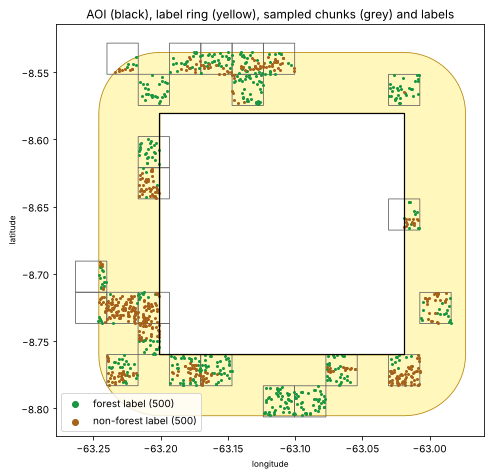

,labels
ring,"0 to 5 km around the AOI, 47,697 ha, buffered in EPSG:32720"
ring pixels that are forest / non-forest labels,"3,308,026 / 998,199"
"chunks holding labels (with forest, with non-forest)","112 (112, 101)"
chunks sampled,24
labels sampled / used,1000 / 1000
dropped: no data / other radar regime,0 / 0
labels inside the AOI,0
"non-forest labels with low cover, no loss",0
non-forest labels cleared 2001 to 2017,500
forest labels Hansen records lost after 2019,201


In [5]:
aoi = load_aoi("rondonia")
reader = io.TesseraReader.open()  # metadata only, until section 9
plan = io.plan_aoi(reader, aoi.geometry)
zone = plan.zones[0]
grid = reader.grid(zone.zone)
chunk_h, chunk_w = reader.chunk_shape(zone.zone)
ring = deforest.label_ring(aoi.geometry, outer_km=ring_rec["outer_km"], inner_km=ring_rec["inner_km"])
labels = pd.read_parquet(result.extra_paths["labels"])
to_lonlat = grid.to_lonlat()


def chunk_polygon(key: str) -> Polygon:
    """The footprint of a store chunk ``zone/chunk_row/chunk_col`` in lon/lat."""
    _, r, c = key.split("/")
    x0 = grid.left + int(c) * chunk_w * grid.pixel
    y0 = grid.top - int(r) * chunk_h * grid.pixel
    xs = [x0, x0 + chunk_w * grid.pixel, x0 + chunk_w * grid.pixel, x0]
    ys = [y0, y0, y0 - chunk_h * grid.pixel, y0 - chunk_h * grid.pixel]
    lon, lat = to_lonlat.transform(xs, ys)
    return Polygon(zip(lon, lat, strict=True))


fig, ax = plt.subplots(figsize=(7.5, 6.5), layout="constrained")
gpd.GeoSeries([ring.geometry]).plot(ax=ax, facecolor="#fff7bc", edgecolor="#b8860b", linewidth=0.8)
gpd.GeoSeries([chunk_polygon(k) for k in labels_rec["chunks"]]).plot(
    ax=ax, facecolor="none", edgecolor="#636363", linewidth=0.8
)
gpd.GeoSeries([aoi.geometry]).boundary.plot(ax=ax, color="black", linewidth=1.2)
for value, color, name in ((1, "#1a9641", "forest"), (0, "#a6611a", "non-forest")):
    sel = labels[labels["label"] == value]
    ax.scatter(sel["lon"], sel["lat"], s=4, color=color, label=f"{name} label ({len(sel)})")
ax.set_title("AOI (black), label ring (yellow), sampled chunks (grey) and labels")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.legend(loc="lower left", markerscale=3)
plt.show()

nonforest = labels[labels["label"] == 0]
pd.Series(
    {
        "ring": f"{ring.describe()}, {ring_rec['area_ha']:,.0f} ha, buffered in EPSG:{ring_rec['buffer_epsg']}",
        "ring pixels that are forest / non-forest labels": (
            f"{labels_rec['ring_pixels_forest']:,} / {labels_rec['ring_pixels_nonforest']:,}"
        ),
        "chunks holding labels (with forest, with non-forest)": (
            f"{labels_rec['chunks_with_labels']} ({labels_rec['chunks_with_forest']}, "
            f"{labels_rec['chunks_with_nonforest']})"
        ),
        "chunks sampled": labels_rec["chunks_used"],
        "labels sampled / used": (
            f"{labels_rec['sampled']} / {labels_rec['used_forest'] + labels_rec['used_nonforest']}"
        ),
        "dropped: no data / other radar regime": f"{labels_rec['dropped_no_data']} / {labels_rec['dropped_regime']}",
        "labels inside the AOI": int(labels["inside_aoi"].sum()),
        "non-forest labels with low cover, no loss": int((nonforest["hansen_lossyear"] == 0).sum()),
        "non-forest labels cleared 2001 to 2017": int((nonforest["hansen_lossyear"] > 0).sum()),
        "forest labels Hansen records lost after 2019": int(
            ((labels["label"] == 1) & (labels["hansen_lossyear"] > YEAR_A - 2000)).sum()
        ),
    },
    name="labels",
).to_frame()

Note what the non-forest class is made of. In 2000 this whole landscape was forest (Hansen tree cover of at
least 90% on 99.96% of the ring's land), so the low-cover rule finds nothing and all 500 non-forest labels are
land Hansen records as cleared between 2001 and 2017: pasture and old clearings. By construction the class holds
**no fresh clearing**: pixels cleared in 2018 or 2019 are not labels at all, because their 2019 embedding may show
either state. That keeps the labels clean, and sections 6 and 9 show it has a cost. The 201 forest labels that
Hansen records as lost after 2019 are still correct labels for 2019; the transfer check in section 8 leaves them
out.

## 4. Forest in both years

Bands 1 and 2 of the COG are the forest probabilities. Below: forest (`p >= 0.5`) in 2019 and 2022, and, for
comparison, Hansen's forest proxy for 2019 (tree cover in 2000 at least 50% and no loss through 2019). The
images show every third pixel.

bands: ['forest_prob_2019', 'forest_prob_2022', 'distance_2019_2022', 'converted']


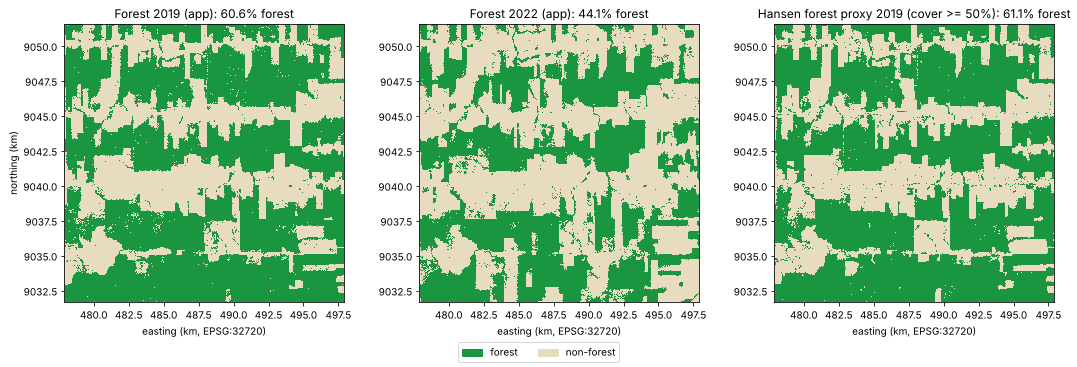

,2019,2022
forest area (ha),24069.180,17497.270
forest share of classified pixels,0.606,0.441
agreement with Hansen proxy (cover >= 50%): accuracy,0.950,0.930
recall forest,0.955,0.976
recall non-forest,0.942,0.901
"Hansen proxy forest share, cover >= 50%",0.611,NaN
"Hansen proxy forest share, cover >= 30% (hansen_forest default)",0.611,NaN


In [6]:
with rasterio.open(result.paths.tif) as ds:
    band_names = list(ds.descriptions)
    prob_a, prob_b, dist, conv = ds.read()
    extent, tif_transform = plotting_extent(ds), ds.transform
extent_km = tuple(v / 1000 for v in extent)  # maps below are in km of UTM 20S
assert tif_transform == zone.transform  # one zone: the mosaic is the zone plan's own grid
print("bands:", band_names)

lossyear = validate.hansen_layer(zone, "lossyear")
cover = validate.hansen_layer(zone, "treecover2000")
land = validate.hansen_valid(zone)
hansen_forest = {thr: validate.hansen_forest(zone, YEAR_A, threshold=thr) for thr in (30, 50)}

with np.errstate(invalid="ignore"):
    forest_a, forest_b = prob_a >= 0.5, prob_b >= 0.5
has_a, has_b = np.isfinite(prob_a), np.isfinite(prob_b)


def small(a: np.ndarray) -> np.ndarray:
    """Every ``STEP``-th pixel, for display."""
    return a[::STEP, ::STEP]


forest_cmap = ListedColormap(["#e8dcc0", "#1a9641"]).with_extremes(bad=GREY)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
images = [
    (np.where(has_a, forest_a, np.nan), f"Forest {YEAR_A} (app)"),
    (np.where(has_b, forest_b, np.nan), f"Forest {YEAR_B} (app)"),
    (np.where(zone.mask & land, hansen_forest[50], np.nan), f"Hansen forest proxy {YEAR_A} (cover >= 50%)"),
]
for ax, (img, title) in zip(axes, images, strict=True):
    ax.imshow(
        np.ma.masked_invalid(small(img)), cmap=forest_cmap, vmin=0, vmax=1, extent=extent_km, interpolation="nearest"
    )
    ax.set_title(f"{title}: {np.nanmean(img):.1%} forest")
    ax.set_xlabel(f"easting (km, EPSG:{grid.epsg})")
axes[0].set_ylabel("northing (km)")
fig.legend(
    handles=[Patch(color="#1a9641", label="forest"), Patch(color="#e8dcc0", label="non-forest")],
    loc="outside lower center",
    ncols=2,
)
plt.show()

agree_a, agree_b = val["forest_agreement_year_a"], val["forest_agreement_year_b"]
pd.DataFrame(
    {
        f"{YEAR_A}": {
            "forest area (ha)": summary["forest_ha_year_a"],
            "forest share of classified pixels": summary["forest_fraction_year_a"],
            "agreement with Hansen proxy (cover >= 50%): accuracy": agree_a["accuracy"],
            "  recall forest": agree_a["recall_forest"],
            "  recall non-forest": agree_a["recall_nonforest"],
            "Hansen proxy forest share, cover >= 50%": float(hansen_forest[50][zone.mask & land].mean()),
            "Hansen proxy forest share, cover >= 30% (hansen_forest default)": float(
                hansen_forest[30][zone.mask & land].mean()
            ),
        },
        f"{YEAR_B}": {
            "forest area (ha)": summary["forest_ha_year_b"],
            "forest share of classified pixels": summary["forest_fraction_year_b"],
            "agreement with Hansen proxy (cover >= 50%): accuracy": agree_b["accuracy"],
            "  recall forest": agree_b["recall_forest"],
            "  recall non-forest": agree_b["recall_nonforest"],
        },
    }
)

The 2019 forest map agrees with Hansen's proxy on 95% of the AOI, and finds 60.6% forest against the proxy's
61.1%. Tree cover in 2000 was at least 90% on 99.96% of the AOI, so the proxy is the same at the 30% cut most GFC
studies use and at the app's 50% (61.1% both): here the proxy is simply "forest in 2000 and not lost since". The
2022 map agrees on 93%: its non-forest recall is lower (0.90), because some land Hansen records as cleared by 2022
still reads as forest (section 6).

## 5. Conversion over Hansen loss, 2020 to 2022

Band 4 of the COG is the conversion (1 converted, 0 not, no data where a pixel was not classified). On the left,
conversion in red over the 2019 forest, with the outline of Hansen loss in 2020 to 2022 in blue; on the right,
where the two agree: converted and Hansen loss (dark red), converted only (orange), Hansen loss only (blue).

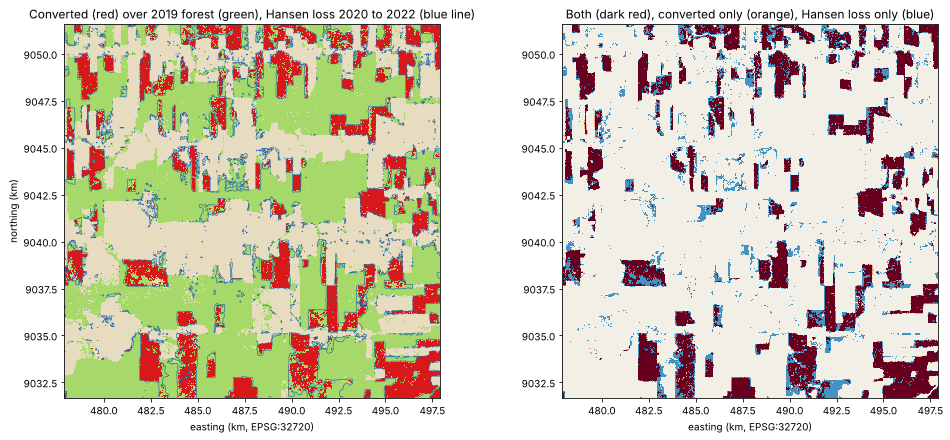

In [7]:
classified = np.isfinite(conv) & land
converted = conv == 1
ref = (lossyear > YEAR_A - 2000) & (lossyear <= YEAR_B - 2000) & classified
tp, fp, fn = converted & ref, converted & ~ref & classified, ref & ~converted

state = np.full(conv.shape, np.nan, dtype=np.float32)
state[has_a & ~forest_a] = 0
state[forest_a] = 1
state[converted] = 2
agree = np.full(conv.shape, np.nan, dtype=np.float32)
agree[classified] = 0
agree[tp] = 1
agree[fp] = 2
agree[fn] = 3

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
axes[0].imshow(
    np.ma.masked_invalid(small(state)),
    cmap=ListedColormap(["#e8dcc0", "#a6d96a", "#d7191c"]).with_extremes(bad=GREY),
    vmin=-0.5,
    vmax=2.5,
    extent=extent_km,
    interpolation="nearest",
)
axes[0].contour(
    small(ref).astype(float), levels=[0.5], colors=["#2166ac"], linewidths=0.6, extent=extent_km, origin="upper"
)
axes[0].set_title(f"Converted (red) over {YEAR_A} forest (green), Hansen loss 2020 to 2022 (blue line)")
axes[1].imshow(
    np.ma.masked_invalid(small(agree)),
    cmap=ListedColormap(["#f2efe6", "#67001f", "#f4a582", "#4393c3"]).with_extremes(bad=GREY),
    vmin=-0.5,
    vmax=3.5,
    extent=extent_km,
    interpolation="nearest",
)
axes[1].set_title("Both (dark red), converted only (orange), Hansen loss only (blue)")
for ax in axes:
    ax.set_xlabel(f"easting (km, EPSG:{grid.epsg})")
axes[0].set_ylabel("northing (km)")
plt.show()

The scores below come from `deforest_validation.json`, computed by the app over every classified AOI pixel on
Hansen land. The headline reference is Hansen loss *after* 2019 *through* 2022 (lossyear codes 20 to 22), the
window a 2019 to 2022 conversion corresponds to (survey S13). The brief's checkpoint asks for "precision and
recall against Hansen loss for Rondonia 2022"; the second row is that narrower comparison, against loss in 2022
alone. The third row scores the lag-aligned window, loss in 2019 through 2021, which the app reports in case the
annual embeddings lag the loss by a year.

In [8]:
lag, only_b = val["lag_aligned"], val["year_b_only"]
scores = pd.DataFrame(
    {
        f"loss after {YEAR_A} through {YEAR_B} (headline)": {
            "IoU": val["iou"],
            "precision": val["precision"],
            "recall": val["recall"],
            "F1": val["f1"],
            "Hansen loss pixels scored": val["reference_pixels_scored"],
        },
        f"loss in {YEAR_B} only (the brief's checkpoint)": {
            "precision": only_b["precision"],
            "recall": only_b["recall"],
            "Hansen loss pixels scored": only_b["reference_pixels_scored"],
        },
        f"loss in {YEAR_A} through {YEAR_B - 1} (lag-aligned)": {
            "IoU": lag["iou"],
            "precision": lag["precision"],
            "recall": lag["recall"],
            "F1": lag["f1"],
            "Hansen loss pixels scored": lag["reference_pixels_scored"],
        },
    }
).T
scores.map(lambda x: "" if pd.isna(x) else (f"{int(x):,}" if x > 1 else f"{x:.3f}"))

,IoU,precision,recall,F1,Hansen loss pixels scored
loss after 2019 through 2022 (headline),0.657,0.976,0.668,0.793,"879,243"
loss in 2022 only (the brief's checkpoint),,0.351,0.731,,"288,863"
loss in 2019 through 2021 (lag-aligned),0.384,0.629,0.496,0.555,"763,301"


In [9]:
breakdown = pd.DataFrame(val["loss_year_breakdown"]).T
columns = {
    "pixels": "scored pixels",
    "converted_share": "converted",
    "flip_share": "flipped by the classifier",
    "below_cut_share": "flipped, removed by the cut",
}
shown = breakdown.loc[[str(y) for y in range(2016, 2026)] + ["no_loss"], list(columns)].rename(columns=columns)
shown["scored pixels"] = shown["scored pixels"].astype(int).map(lambda x: f"{x:,}")
for col in list(columns.values())[1:]:
    shown[col] = shown[col].map(lambda x: f"{x:.3f}")
shown.index.name = "Hansen loss year"
shown

,scored pixels,converted,flipped by the classifier,"flipped, removed by the cut"
Hansen loss year,,,,
2016,"297,089",0.004,0.017,0.008
2017,"205,447",0.008,0.025,0.011
2018,"247,893",0.024,0.096,0.048
2019,"172,921",0.014,0.058,0.019
2020,"333,252",0.680,0.839,0.094
2021,"257,128",0.582,0.722,0.073
2022,"288,863",0.731,0.831,0.053
2023,"47,288",0.006,0.027,0.016
2024,"119,046",0.002,0.022,0.015


**The loss-year breakdown settles the timing question.** Hansen loss in 2019 is converted on only 1.4% of its
pixels and flipped on 5.8%: the 2019 embedding already reads land cleared in 2019 as non-forest (clearing on this
front typically happens in the dry season, so most of that year's observations see it cleared). Loss in 2020,
2021 and 2022 is converted on 68%, 58% and 73% of its pixels, and loss outside the window on almost none. So on
this front the embeddings do not lag: the headline window `(2019, 2022]` is the aligned one, and the lag-aligned
score (IoU 0.38) is low because it counts 2019 loss, which the app treats as already cleared, and leaves out
2022. The app's window caveat below reports these measured shares, and which of the two windows scores
higher, instead of assuming a lag either way.

**The brief's 2022-only comparison** finds 73% of the 2022 loss, but its precision is 0.35 by construction:
nearly two thirds of the conversions (62%) are 2020 and 2021 loss, which it counts as false.

The caveats the app writes into `deforest_validation.json`:

In [10]:
val_doc = json.loads(result.paths.validation.read_text(encoding="utf-8"))
for caveat in val_doc["caveats"]:
    print("-", caveat)

- Scores count AOI pixels classified in both years (valid, and in the training labels' radar regime in both), in every zone the AOI touches; with Hansen, only pixels Hansen maps as land (datamask 1).
- Hansen Global Forest Change is itself a model, at 30 m, resampled here to the 10 m grid by nearest neighbour, so disagreement along patch edges is expected.
- Hansen loss records stand-replacing tree cover loss of any cause, including fire, storms and selective or salvage logging followed by regrowth, while a conversion here needs a non-forest classification in year_b: loss that still reads as forest in year_b is a miss by construction, and regrowth after early loss in the window can hide it.
- The headline reference is Hansen loss after 2019 through 2022 (lossyear codes 20 to 22), as survey S13 specifies. Annual embeddings and Hansen's detection year need not line up: loss Hansen dates to 2019 may already read as cleared in the 2019 embedding, and loss it dates to 2022 may still read as

## 6. Where the app and Hansen disagree

Precision is 0.976: almost everything the app calls converted is Hansen loss in the window. Recall is 0.668: a
third of Hansen's loss pixels are not called converted. The cell below takes the disagreement apart on the COG's
grid, using Hansen's `lossyear` (cached windows from the public bucket). Nothing here changes
the run or its parameters; it explains the numbers above.

- **Each missed pixel** is put in the step of the method that lost it: the classifier already called it
  non-forest in 2019; it called it forest in both years (with the embedding nearly unchanged, or changed); it
  flipped to non-forest but the cross-check cut removed it; or the cleaning (3 x 3 opening, 0.5 ha) removed it.
- **Edges.** Hansen is a 30 m product resampled to 10 m, so every Hansen edge is a 30 m staircase. A pixel within
  30 m (one Hansen pixel) of the boundary of Hansen's loss is counted as an edge pixel.

In [11]:
with np.errstate(invalid="ignore"):
    flip = forest_a & ~forest_b
cut, ring_cut = cross["cut"], cross["ring_label_cut"]
inside = ndimage.distance_transform_edt(ref)
outside = ndimage.distance_transform_edt(~ref)
near_edge = np.where(ref, inside, outside) <= 3  # within 30 m of the boundary of Hansen loss
missed = {
    f"called non-forest in {YEAR_A} already": fn & ~forest_a,
    f"forest in both years, embedding nearly unchanged (distance <= {ring_cut:.3f})": fn
    & forest_a
    & forest_b
    & (dist <= ring_cut),
    f"forest in both years, embedding changed (distance > {ring_cut:.3f})": fn
    & forest_a
    & forest_b
    & (dist > ring_cut),
    f"flipped to non-forest, distance <= the cut {cut:.3f}": fn & flip & (dist <= cut),
    "flipped, above the cut, removed by the opening or the 0.5 ha minimum": fn & flip & (dist > cut),
}
rows = {"MISSED (share of Hansen loss)": (fn.sum() / ref.sum(), near_edge[fn].mean(), None, None, None)}
for name, m in missed.items():
    per_year = [(m & (lossyear == y)).sum() / (fn & (lossyear == y)).sum() for y in (20, 21, 22)]
    rows[f"  {name}"] = (m.sum() / fn.sum(), near_edge[m].mean(), *per_year)
extra = {
    "Hansen loss in 2018 or 2019 (just before the window)": (lossyear >= 18) & (lossyear <= 19),
    "Hansen loss in 2001 to 2017": (lossyear >= 1) & (lossyear <= 17),
    "Hansen loss after 2022": lossyear > YEAR_B - 2000,
    "no Hansen loss": lossyear == 0,
}
rows["EXTRA (share of converted)"] = (fp.sum() / converted.sum(), near_edge[fp].mean(), None, None, None)
for name, m in extra.items():
    rows[f"  {name}"] = ((fp & m).sum() / fp.sum(), near_edge[fp & m].mean(), None, None, None)
columns = ["share", "within 30 m of a Hansen edge", "share, 2020 loss", "share, 2021 loss", "share, 2022 loss"]
diag = pd.DataFrame.from_dict(rows, orient="index", columns=columns)
diag.index.name = f"missed: {fn.sum():,} pixels; extra: {fp.sum():,} pixels"
diag.map(lambda x: "" if x is None or pd.isna(x) else f"{x:.3f}")

,share,within 30 m of a Hansen edge,"share, 2020 loss","share, 2021 loss","share, 2022 loss"
"missed: 292,050 pixels; extra: 14,632 pixels",,,,,
MISSED (share of Hansen loss),0.332,0.530,,,
called non-forest in 2019 already,0.171,0.827,0.219,0.164,0.117
"forest in both years, embedding nearly unchanged (distance <= 0.153)",0.105,0.824,0.093,0.093,0.137
"forest in both years, embedding changed (distance > 0.153)",0.318,0.518,0.190,0.407,0.372
"flipped to non-forest, distance <= the cut 0.244",0.225,0.343,0.295,0.174,0.198
"flipped, above the cut, removed by the opening or the 0.5 ha minimum",0.181,0.332,0.203,0.163,0.176
EXTRA (share of converted),0.024,0.915,,,
Hansen loss in 2018 or 2019 (just before the window),0.572,0.880,,,
Hansen loss in 2001 to 2017,0.355,0.962,,,


In [12]:
away = ~near_edge & classified
lab, n_patches = ndimage.label(ref, structure=np.ones((3, 3)))
size_px = np.bincount(lab.ravel())[1:]
found_px = np.bincount(lab.ravel(), weights=converted.ravel())[1:]
bins = np.searchsorted([metrics.area_to_pixels(e) for e in deforest.PATCH_BIN_EDGES_HA], size_px, side="right")
by_size = pd.DataFrame(
    {
        "Hansen loss patches": np.bincount(bins, minlength=6),
        "share of Hansen loss area": np.bincount(bins, weights=size_px, minlength=6) / ref.sum(),
        "recall (area)": np.bincount(bins, weights=found_px, minlength=6)
        / np.maximum(1, np.bincount(bins, weights=size_px, minlength=6)),
        "patches touched by a conversion": np.bincount(bins, weights=found_px > 0, minlength=6)
        / np.maximum(1, np.bincount(bins, minlength=6)),
    },
    index=pd.Index(deforest.PATCH_BIN_LABELS, name="Hansen loss patch (ha)"),
)
pixel_size = np.concatenate([[0], size_px])[lab]
small_loss = ref & (pixel_size < metrics.area_to_pixels(5.0))
print(
    f"Pixels of Hansen patches under 5 ha: {small_loss.sum():,}; non-forest in {YEAR_A} already "
    f"{(small_loss & ~forest_a).sum() / small_loss.sum():.0%}, forest in both years "
    f"{(small_loss & forest_a & forest_b).sum() / small_loss.sum():.0%}, flipped "
    f"{(small_loss & flip).sum() / small_loss.sum():.0%}"
)
print(
    f"Away from Hansen edges (more than 30 m): recall {(tp & away).sum() / (ref & away).sum():.3f}, "
    f"precision {(tp & away).sum() / (converted & away).sum():.3f}; within 30 m: recall "
    f"{(tp & near_edge).sum() / (ref & near_edge).sum():.3f}. Edge pixels are {near_edge[ref].mean():.0%} of "
    f"Hansen loss and {near_edge[tp].mean():.0%} of the pixels found."
)
by_size

Pixels of Hansen patches under 5 ha: 41,435; non-forest in 2019 already 42%, forest in both years 35%, flipped 23%
Away from Hansen edges (more than 30 m): recall 0.794, precision 0.998; within 30 m: recall 0.273. Edge pixels are 24% of Hansen loss and 10% of the pixels found.


,Hansen loss patches,share of Hansen loss area,recall (area),patches touched by a conversion
Hansen loss patch (ha),,,,
<0.5,850,0.014,0.004,0.008
0.5-1,92,0.007,0.026,0.054
1-5,101,0.026,0.077,0.158
5-20,37,0.048,0.300,0.649
20-100,38,0.185,0.630,1.000
>100,25,0.721,0.742,1.000


**Reading it.** Nothing was tuned: the labels, the classifier, the 0.5 forest cut, the cross-check percentile and
the cleaning are all defaults, and Hansen was fixed as the reference before the run.

- **Edges are the largest single part of the disagreement.** 53% of the missed pixels and 92% of the extra
  pixels lie within 30 m of the boundary of Hansen's loss, against 10% of the pixels both agree on. Away from
  that band recall is 0.79 and precision 0.998; inside it recall is 0.27. A 30 m staircase and a 10 m map cannot
  agree pixel for pixel along an edge, and the clearings here are large and long-edged.
- **Small Hansen patches are rarely found.** Patches under 5 ha are 5% of Hansen's loss area and the app
  converts about 5% of it; patches over 100 ha are 72% of the area and 74% of it is converted. Of the pixels in
  the small patches, 42% were already non-forest in the 2019 map (slivers along older clearings) and 35% still
  read as forest in 2022 (loss that left a canopy, or does not show at 10 m); only 23% flipped, and the 3 x 3
  opening and the 0.5 ha minimum remove most of those. Hansen records stand-replacing loss of any cause, including
  selective logging, fire in standing forest and storms, which a conversion map should not count; with no fire or
  logging product reachable from this environment, the two cannot be told apart here.
- **"Forest in both years" is the largest step of the method that misses** (42% of missed pixels). A tenth of
  missed pixels have an embedding that barely changed (most of them on edges: Hansen loss the 10 m pixel does
  not show). About a third changed strongly but still read as forest in 2022. That share is 19% for 2020 loss,
  41% for 2021 loss and 37% for 2022 loss. If regrowth were the cause it would be largest for the oldest loss, so
  it is mostly not regrowth: a clearing one year old or less still carries felled trees, slash and burning,
  and a clearing late in 2022 is only part of that year's observations. The classifier's non-forest labels
  never include a fresh clearing (section 3), so it has not been shown what one looks like.
- **The cross-check cut removed 22% of the missed pixels.** See the next cell.
- **The cleaning removed 18%**, a third of them on edges: thin strips and the margins of patches.
- **The extra pixels are few** (2.4% of the conversion), and 92% of them are on Hansen edges. By Hansen loss
  year, 57% of them are loss Hansen dates to 2018 or 2019, just before the window (a timing disagreement), and
  36% loss in 2017 or earlier: most likely land that regrew after an earlier clearing and was cleared again in the
  window, which Hansen cannot record, since its `lossyear` holds one year per pixel.
- **Label noise** bounds what any classifier can do with these labels: on held-out chunks 4.4% of the labels are
  misclassified (section 8), a mix of classifier error and labels whose Hansen class is not the land's.

### The cross-check cut

The cut is the 95th percentile of the 2019 to 2022 distance among pixels classed forest in both years (survey
N13). On a front where a quarter of the forest converts, that set also holds conversions the classifier still
calls forest in 2022, and they raise the percentile. The app already warns about this without looking at the
reference: the same percentile among the 348 ring forest labels Hansen keeps unchanged is 0.153, and the AOI cut
is 1.60 times that. The cell below measures what the cut costs, against the same reference, as a diagnosis
only: the headline numbers above stay the default run's, and picking a cut by its score against Hansen would be
tuning to the answer.

In [13]:
stable_forest = classified & forest_a & forest_b
print(
    f"Pixels forest in both years: {stable_forest.sum():,}; of them Hansen loss in the window: "
    f"{(stable_forest & ref).sum() / stable_forest.sum():.1%}. 95th percentile of their distance: {cut:.3f}; "
    f"of those with no Hansen loss at all: {np.percentile(dist[stable_forest & (lossyear == 0)], 95):.3f}"
)
min_px = metrics.area_to_pixels(summary["min_area_ha"])
sens = {}
for name, value in (("no cross-check", None), ("ring label cut", ring_cut), ("AOI cut (the app's)", cut)):
    raw = deforest.conversion_mask(prob_a, prob_b, dist, cut=value)
    kept = metrics.clean_mask(raw & zone.mask, min_pixels=min_px, opening=3) & classified
    hit = (kept & ref).sum()
    sens[name] = {
        "cut": np.nan if value is None else value,
        "converted (ha)": kept.sum() * io.HA_PER_PIXEL,
        "precision": hit / kept.sum(),
        "recall": hit / ref.sum(),
        "IoU": hit / (kept | ref).sum(),
    }
    if value == cut:
        assert np.array_equal(kept, converted & classified)  # the same cleaning reproduces the app's band
pd.DataFrame(sens).T

Pixels forest in both years: 1,640,658; of them Hansen loss in the window: 7.5%. 95th percentile of their distance: 0.244; of those with no Hansen loss at all: 0.172


,cut,converted (ha),precision,recall,IoU
no cross-check,NaN,7060.04,0.958,0.769,0.744
ring label cut,0.153,6883.37,0.964,0.755,0.735
AOI cut (the app's),0.244,6018.25,0.976,0.668,0.657


Without any cross-check, recall would be 0.77 at a precision of 0.96; with the ring-label cut, 0.76 at 0.96.
Against no cross-check at all, the N13 cut buys 1.8 points of precision for 10 points of recall here. Of the 94,974 classifier flips it removed, 69%
are Hansen loss in the window. This is a finding about the rule, not a parameter to move after the fact: the
brief's checkpoint asked for the numbers, and they are reported as the default run gives them. Whether the
cross-check should be set from the ring's Hansen-stable labels (which the AOI's own conversions cannot raise) is
a design decision to confirm on other AOIs first; section 9 shows the cut is also the least stable part of the
method when labels are few.

## 7. Patch sizes

Patches are the 8-connected components of the cleaned conversion, counted in the bins the app reports. Most
patches are small, and most of the converted area is in a few large ones.

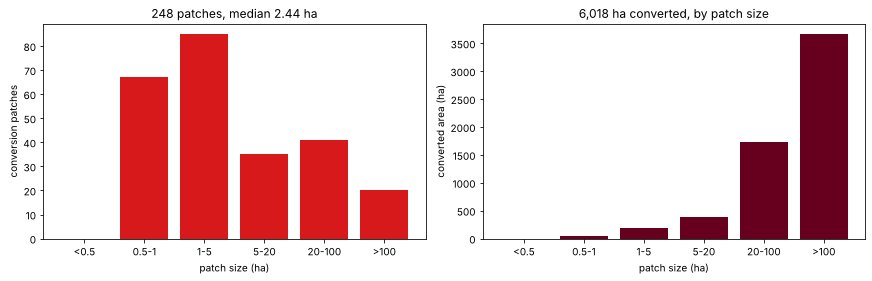

ha,<0.5,0.5-1,1-5,5-20,20-100,>100
patches,0.0,67.000,85.00,35.000,41.000,20.000
area (ha),0.0,46.580,183.49,388.610,1732.880,3666.690
share of area,0.0,0.008,0.03,0.065,0.288,0.609


In [14]:
sizes = metrics.component_sizes(converted)
assert sizes.size == patches["count"]
order = list(deforest.PATCH_BIN_LABELS)
counts = [patches["histogram"][k] for k in order]  # the report stores the bins in text order
which = np.searchsorted([metrics.area_to_pixels(e) for e in deforest.PATCH_BIN_EDGES_HA], sizes, side="right")
area = np.bincount(which, weights=sizes * io.HA_PER_PIXEL, minlength=len(order))
assert list(np.bincount(which, minlength=len(order))) == counts

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
axes[0].bar(order, counts, color="#d7191c")
axes[0].set_ylabel("conversion patches")
axes[0].set_title(f"{patches['count']} patches, median {patches['median_ha']:.2f} ha")
axes[1].bar(order, area, color="#67001f")
axes[1].set_ylabel("converted area (ha)")
axes[1].set_title(f"{summary['converted_ha']:,.0f} ha converted, by patch size")
for ax in axes:
    ax.set_xlabel("patch size (ha)")
plt.show()
pd.DataFrame(
    {"patches": counts, "area (ha)": area, "share of area": area / area.sum()}, index=pd.Index(order, name="ha")
).T

Twenty patches over 100 ha hold most of the converted area: the large, regular clearings typical of this front.
The 67 patches between 0.5 and 1 ha are the ones closest to the minimum area; raising `--min-area-ha` to 1 ha
would drop them and change the converted area by under 1%.

## 8. Classifier skill

The held-out estimate is spatial: labels are grouped by their store chunk (2.56 km), and each of 5 folds holds out
whole chunks. The transfer check scores the same classifier on 2022 embeddings at the ring labels Hansen keeps
unchanged through 2022 (all non-forest labels, and forest labels with no loss through 2022).

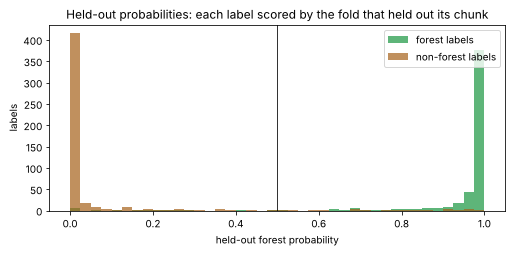

,training (in sample),held out by store chunk,"same labels, 2019 held out","2022, Hansen-stable labels"
n,1000,1000,848,848
accuracy,0.974,0.956,0.953,0.938
balanced_accuracy,0.974,0.956,0.954,0.946
recall_forest,0.976,0.964,0.960,0.994
recall_nonforest,0.972,0.948,0.948,0.898


,chunks,labels,forest share,recall forest,recall non-forest,balanced accuracy
fold 0,4,193,0.40,0.948,0.991,0.970
fold 1,5,203,0.50,0.970,1.000,0.985
fold 2,5,202,0.66,0.985,0.913,0.949
fold 3,5,200,0.37,0.959,0.952,0.956
fold 4,5,202,0.57,0.948,0.851,0.899


In [15]:
held, train, transfer = clf["heldout"], clf["training"], summary["transfer"]
keys = ["n", "accuracy", "balanced_accuracy", "recall_forest", "recall_nonforest"]
skill = pd.DataFrame(
    {
        "training (in sample)": train,
        "held out by store chunk": held,
        f"same labels, {YEAR_A} held out": transfer["year_a_heldout"],
        f"{YEAR_B}, Hansen-stable labels": transfer["year_b"],
    }
).loc[keys]
skill = skill.map(lambda x: f"{int(x)}" if x > 1 else f"{x:.3f}")

used = labels[labels["used"]]
folds = {}
for fold, g in used.groupby("fold"):
    pred, truth = g["heldout_prob"] >= 0.5, g["label"] == 1
    rf, rn = pred[truth].mean(), (~pred[~truth]).mean()
    folds[f"fold {fold}"] = {
        "chunks": f"{g['source_chunk'].nunique()}",
        "labels": f"{len(g)}",
        "forest share": f"{truth.mean():.2f}",
        "recall forest": f"{rf:.3f}",
        "recall non-forest": f"{rn:.3f}",
        "balanced accuracy": f"{(rf + rn) / 2:.3f}",
    }

fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
for value, color, name in ((1, "#1a9641", "forest labels"), (0, "#a6611a", "non-forest labels")):
    ax.hist(used.loc[used["label"] == value, "heldout_prob"], bins=40, range=(0, 1), color=color, alpha=0.7, label=name)
ax.axvline(0.5, color="black", linewidth=0.8)
ax.set_xlabel("held-out forest probability")
ax.set_ylabel("labels")
ax.set_title("Held-out probabilities: each label scored by the fold that held out its chunk")
ax.legend()
plt.show()
display(skill)
pd.DataFrame(folds).T

The classifier separates the two label classes well and the estimate is honest about space: 0.956 balanced
accuracy on chunks it never saw, against 0.974 in sample, with folds between 0.90 and 0.99. It
transfers to 2022 with a drop of under 1 point on the Hansen-stable labels (0.946); the one thing that weakens
in 2022 is non-forest recall (0.90), the same pattern as the forest map agreement in section 4. These scores
measure how well the embedding separates the *label* classes; they do not see fresh clearings, which are not
labels (section 3), and that is where the conversion loses recall.

## 9. Running where no forest layer exists

Hansen is global, but its tree cover is not everyone's forest: dry forest, woodland savanna, plantations told
apart from natural forest, or a national forest definition all need labels of their own, and for many other land
covers there is no layer at all. This is where the app has the most value: the embeddings already separate land
covers, so a few dozen labelled points can stand in for a global product. This section shows the workflow end to
end:

1. **Label points.** A CSV with columns `lon`, `lat`, `label` (1 forest, 0 non-forest) and an optional
   `weight`, describing `year_a`. Labels come from photo interpretation of high-resolution imagery, field visits,
   or a local map. The app checks the file before it opens the store: columns, label values, coordinates, and at
   least 20 labels per class.
2. **Run** with `--labels`. Validate only if you have a reference (`--reference path`, any vector or GeoTIFF);
   with no reference at all, the held-out score on your own labels is the skill estimate.

```
tessera-apps deforest --aoi my_aoi.geojson --year-a 2019 --year-b 2022 --labels my_labels.csv --out out/my_run
```

**The labels below are stand-ins, not hand labels.** To have a reference to score against, they are drawn from
the Hansen-derived ring labels of section 3. Real hand labels are noisier, and they are not tied to Hansen, so
they would neither share its errors nor be flattered by them. They would also be spread wider than 24 chunks.

### 9.1 A run on 50 labels per class

The cell writes 50 forest and 50 non-forest stand-in labels to a CSV and runs the app with it on the whole AOI,
validating against Hansen as before. It reads the AOI again (about 1.3 GB), unless `out/deforest_csv` already
holds current outputs.

In [16]:
pool = labels[labels["used"]].reset_index(drop=True)
y_pool = pool["label"].to_numpy(dtype=np.int64)
groups_pool = pool["source_chunk"].to_numpy()


def stand_in(per_class: int, seed: int) -> np.ndarray:
    """Indices of ``per_class`` forest and ``per_class`` non-forest pool labels, drawn without replacement."""
    rng = np.random.default_rng(seed)
    picks = [
        rng.choice(np.flatnonzero(y_pool == c), per_class, replace=False) for c in (deforest.FOREST, deforest.NONFOREST)
    ]
    return np.sort(np.concatenate(picks))


LABELS_CSV = Path("out/deforest_standin_labels.csv")
pool.loc[stand_in(50, 0), ["lon", "lat", "label"]].to_csv(LABELS_CSV, index=False, float_format="%.7f")
print(LABELS_CSV.read_text(encoding="utf-8")[:160], "...")

csv_result = run_deforest("rondonia", YEAR_A, YEAR_B, "out/deforest_csv", validate=True, labels=LABELS_CSV)
print("skipped (outputs current):", csv_result.skipped)

lon,lat,label
-63.1319845,-8.5351701,1
-63.1733290,-8.5352443,1
-63.1402535,-8.5353481,1
-63.1733292,-8.5356966,1
-63.1105402,-8.5363527,1
-63.1152654,-8.536532 ...


INFO tessera_apps.apps._common: deforest: AOI demo:rondonia, 39,717 ha in 1 zone(s) (20S 1988 x 2001), 3,971,688 pixels; years 2019, 2022; at most 1.95 GB of chunks to read.


INFO tessera_apps.apps._common: deforest: peak memory about 1.5 GB (15.3 GB available).


INFO tessera_apps.apps.deforest: deforest: 100 labels (csv) in 21 chunks, at most 0.19 GB of chunks to read for them (2019).


INFO tessera_apps.apps._common: deforest: removed the previous run's deforest_report.json, deforest_validation.json.


INFO tessera_apps.io: read_points: 100 points from 21 chunks


INFO tessera_apps.apps._common: deforest: read 1.33 GB in 48.7 s (27 MB/s).


skipped (outputs current): False


In [17]:
def headline(s: dict) -> dict:
    """The numbers to compare between two runs, formatted."""
    v, c = s["validation"], s["classifier"]
    values = {
        "labels (forest + non-forest)": f"{c['labels_forest']} + {c['labels_nonforest']}",
        "label source": s["label_source"],
        "held-out balanced accuracy": c["heldout"]["balanced_accuracy"],
        f"forest {YEAR_A} share": s["forest_fraction_year_a"],
        f"forest {YEAR_B} share": s["forest_fraction_year_b"],
        f"{YEAR_A} forest agreement with Hansen proxy": v["forest_agreement_year_a"]["accuracy"],
        f"{YEAR_B} forest agreement with Hansen proxy": v["forest_agreement_year_b"]["accuracy"],
        "cross-check cut": s["cross_check"]["cut"],
        "converted (ha)": s["converted_ha"],
        "precision, loss 2020 to 2022": v["precision"],
        "recall, loss 2020 to 2022": v["recall"],
        "IoU, loss 2020 to 2022": v["iou"],
        "precision, loss 2022 only": v["year_b_only"]["precision"],
        "recall, loss 2022 only": v["year_b_only"]["recall"],
    }
    return {k: x if isinstance(x, str) else (f"{x:,.0f}" if x > 1 else f"{x:.3f}") for k, x in values.items()}


csv_summary = csv_result.summary
for warning in csv_result.report["warnings"]:
    print("WARNING:", warning)
pd.DataFrame({"Hansen ring labels, 500 per class": headline(summary), "CSV, 50 per class": headline(csv_summary)})

,"Hansen ring labels, 500 per class","CSV, 50 per class"
labels (forest + non-forest),500 + 500,50 + 50
label source,hansen,csv
held-out balanced accuracy,0.956,0.920
forest 2019 share,0.606,0.625
forest 2022 share,0.441,0.458
2019 forest agreement with Hansen proxy,0.950,0.939
2022 forest agreement with Hansen proxy,0.930,0.910
cross-check cut,0.244,0.331
converted (ha),"6,018","3,007"
"precision, loss 2020 to 2022",0.976,0.977


The `--labels` run is the same command with the same outputs; the report records `label_source: csv` and the
file's sha256. With 50 stand-in labels per class the forest maps stay close to the 500-label run's (2019 forest
62.5% against 60.6%, agreement with Hansen's proxy 0.94 against 0.95), and precision is unchanged (0.977), but
conversion recall halves, from 0.67 to 0.33. The cross-check cut rose from 0.244 to 0.331. Labels from a CSV carry
no `year_b` truth, so the transfer check and the ring-label comparison of the cut, which warned in section 2,
cannot run, and nothing warns here. The learning curve shows that the cut, not the forest map, is what moves.

### 9.2 How many labels? A learning curve

To see how the result depends on the number of labels, the classifier is trained on 25, 50, 100, 250 and 500
stand-in labels per class (five random draws each, one at 500 since that is the whole pool) and applied to the
same AOI embeddings each time. The AOI is read **once**: its two northern 512-row bands (4 of its 8 blocks, half
of its pixels) for 2019 and 2022, kept in memory as int8. The label embeddings are read once too, at their 24
chunks. Each draw then runs the app's own steps on that half: `fit_forest_model`, `classify_block`,
`cross_check_cut`, `conversion_mask`, the 3 x 3 opening and 0.5 ha minimum, and the scores against Hansen.

In [18]:
points = io.read_points(reader, pool["lon"].to_numpy(), pool["lat"].to_numpy(), YEAR_A, with_radar=True)
assert points.valid.all() and points.radar_present.all()
row_bands = sorted({rs.start: rs.stop for rs, _ in zone.blocks((chunk_h, chunk_w), io.DEFAULT_BLOCK)}.items())
half = slice(row_bands[0][0], row_bands[1][1])
wins = reader.read_windows(zone.zone, [YEAR_A, YEAR_B], half, zone.cols, layers=deforest.LAYERS)
half_mask = zone.submask(half, zone.cols)
r = slice(half.start - zone.rows.start, half.stop - zone.rows.start)
print(
    f"half of the AOI: {half_mask.sum():,} pixels; bytes read so far in this notebook: {reader.bytes_read / 1e9:.2f} GB"
)

ref_h, land_h, forest_ref_h = ref[r], land[r], hansen_forest[50][r]
train_radar = summary["radar"]["training_regime"] == "radar"
curve = []
for per_class in (25, 50, 100, 250, 500):
    for seed in range(1 if per_class == len(pool) // 2 else 5):
        pick = stand_in(per_class, seed)
        fit = deforest.fit_forest_model(points.embeddings[pick], y_pool[pick], groups_pool[pick], seed=0)
        pa, pb, d, _ = deforest.classify_block(wins[YEAR_A], wins[YEAR_B], half_mask, fit.model, train_radar)
        cut_h, _ = deforest.cross_check_cut(d, pa, pb)
        scored = np.isfinite(pa) & np.isfinite(pb) & np.isfinite(d) & land_h
        row = {"per_class": per_class, "seed": seed, "cut": cut_h}
        for name, value in (("", cut_h), ("_no_cut", None)):
            raw = deforest.conversion_mask(pa, pb, d, cut=value)
            kept = metrics.clean_mask(raw & half_mask, min_pixels=min_px, opening=3)
            s = validate.binary_scores(kept, ref_h, valid=scored)
            row |= {f"precision{name}": s.precision, f"recall{name}": s.recall}
        ok = np.isfinite(pa) & land_h
        with np.errstate(invalid="ignore"):
            loss_still_forest = pb[ref_h & scored] >= 0.5
        row |= {
            "heldout_balanced_accuracy": fit.record["heldout"]["balanced_accuracy"],
            "forest_agreement_2019": float(((pa >= 0.5) == forest_ref_h)[ok].mean()),
            "loss_still_forest_2022": float(loss_still_forest.mean()),
        }
        curve.append(row)
curve = pd.DataFrame(curve)
app_half = validate.binary_scores(converted[r], ref_h, valid=classified[r])
print(f"The app's own conversion on the same half: precision {app_half.precision:.3f}, recall {app_half.recall:.3f}")
curve.groupby("per_class").agg(["mean", "min", "max"]).drop(columns="seed").T

INFO tessera_apps.io: read_points: 1000 points from 24 chunks


half of the AOI: 1,927,955 pixels; bytes read so far in this notebook: 0.77 GB


The app's own conversion on the same half: precision 0.971, recall 0.661


per_class                         25     50     100    250    500
cut                       mean  0.270  0.320  0.271  0.263  0.243
                          min   0.234  0.205  0.220  0.227  0.243
                          max   0.306  0.381  0.296  0.321  0.243
precision                 mean  0.965  0.967  0.973  0.973  0.971
                          min   0.960  0.948  0.970  0.967  0.971
                          max   0.975  0.977  0.977  0.977  0.971
recall                    mean  0.559  0.339  0.548  0.573  0.661
                          min   0.416  0.104  0.457  0.363  0.661
                          max   0.702  0.755  0.716  0.693  0.661
precision_no_cut          mean  0.928  0.911  0.947  0.940  0.953
                          min   0.908  0.847  0.936  0.903  0.953
                          max   0.960  0.950  0.956  0.958  0.953
recall_no_cut             mean  0.733  0.640  0.708  0.716  0.760
                          min   0.711  0.486  0.667  0.619  0.760
                          max   0.786  0.824  0.788  0.776  0.760
heldout_balanced_accuracy mean  0.976  0.928  0.960  0.956  0.956
                          min   0.960  0.900  0.955  0.948  0.956
                          max   1.000  0.980  0.965  0.964  0.956
forest_agreement_2019     mean  0.941  0.936  0.942  0.939  0.950
                          min   0.929  0.917  0.938  0.927  0.950
                          max   0.951  0.950  0.947  0.947  0.950
loss_still_forest_2022    mean  0.170  0.223  0.174  0.168  0.144
                          min   0.122  0.070  0.101  0.110  0.144
                          max   0.219  0.342  0.200  0.263  0.144

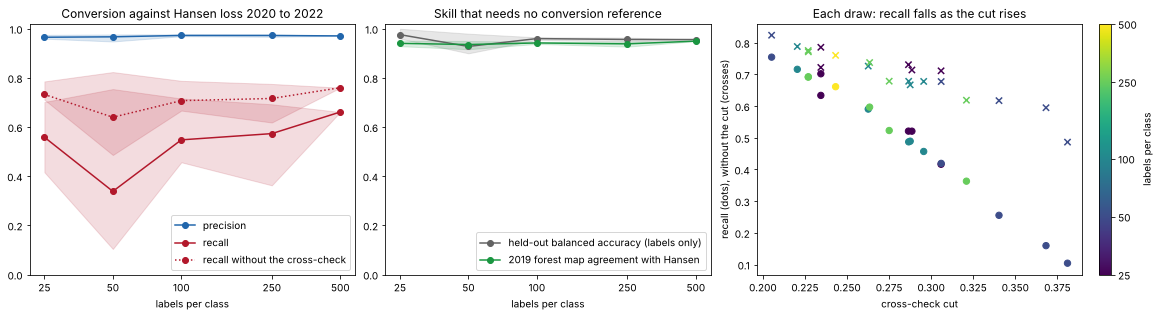

correlation across draws: cut vs share of Hansen loss still forest in 2022 0.95; cut vs recall -0.99


In [19]:
stats = curve.groupby("per_class").agg(["mean", "min", "max"])
x = stats.index.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), layout="constrained")


def band(ax: plt.Axes, column: str, color: str, label: str, style: str = "-") -> None:
    """Mean over the draws, with their range shaded."""
    ax.plot(x, stats[column]["mean"], style, marker="o", color=color, label=label)
    ax.fill_between(x, stats[column]["min"], stats[column]["max"], color=color, alpha=0.15)


band(axes[0], "precision", "#2166ac", "precision")
band(axes[0], "recall", "#b2182b", "recall")
band(axes[0], "recall_no_cut", "#b2182b", "recall without the cross-check", ":")
axes[0].set_title("Conversion against Hansen loss 2020 to 2022")
band(axes[1], "heldout_balanced_accuracy", "#636363", "held-out balanced accuracy (labels only)")
band(axes[1], "forest_agreement_2019", "#1a9641", f"{YEAR_A} forest map agreement with Hansen")
axes[1].set_title("Skill that needs no conversion reference")
for ax in axes[:2]:
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(x, [str(v) for v in x])
    ax.set_xlabel("labels per class")
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower right")
sc = axes[2].scatter(curve["cut"], curve["recall"], c=np.log(curve["per_class"]), cmap="viridis", s=40)
axes[2].scatter(curve["cut"], curve["recall_no_cut"], c=np.log(curve["per_class"]), cmap="viridis", s=40, marker="x")
axes[2].set_xlabel("cross-check cut")
axes[2].set_ylabel("recall (dots), without the cut (crosses)")
axes[2].set_title("Each draw: recall falls as the cut rises")
cbar = fig.colorbar(sc, ax=axes[2], ticks=np.log(x))
cbar.ax.set_yticklabels([str(v) for v in x])
cbar.set_label("labels per class")
plt.show()
print(
    "correlation across draws: cut vs share of Hansen loss still forest in 2022 "
    f"{np.corrcoef(curve['cut'], curve['loss_still_forest_2022'])[0, 1]:.2f}; cut vs recall "
    f"{np.corrcoef(curve['cut'], curve['recall'])[0, 1]:.2f}"
)

**Reading the curve.** At 500 labels per class the notebook reproduces the app's own scores on this half of the
AOI exactly (precision 0.971, recall 0.661), so the curve runs the same method.

- **Precision holds** at 0.95 to 0.98 for every draw from 25 labels per class up.
- **The forest map holds too.** Its agreement with Hansen's proxy is 0.92 to 0.95 from 25 labels per class, and
  the held-out balanced accuracy on the labels themselves is 0.90 to 1.00 for every draw. A few dozen labels per
  class are enough to map forest here.
- **Conversion recall does not hold.** It spans 0.10 to 0.76 across the five draws at 50 labels per class, and
  0.36 to 0.69 at 250, so it does not rise steadily with the label count (the 25-label draws happen to do better
  than the 50-label ones). Across draws it follows the cross-check cut almost exactly (correlation -0.99), and the
  cut follows the share of Hansen's 2020 to 2022 loss that the classifier still calls forest in 2022 (0.95): a
  classifier that calls some fresh clearings forest misses those flips, and by adding them to the "forest in both
  years" set it also raises the cut, which then removes flips it did make. Without the cross-check (dotted line,
  crosses) recall is steadier, 0.49 to 0.82.
- **Nothing in the labels warns about it.** The held-out score cannot see the problem because the stand-in labels
  hold no fresh clearing at all (section 3): every draw is scored on pasture and old clearings, which all draws
  separate from forest well.

What this means for hand labelling, as a hypothesis this notebook does not test: label the cases Hansen-derived
labels leave out, above all fresh clearings, burned slash and young regrowth as non-forest in `year_a`. They pin
down the boundary that decides conversion. And with few labels, read the conversion next to the classifier's own
flips (forest in `year_a`, non-forest in `year_b`, from the two `forest_prob` bands), which do not depend on the
cut.

### 9.3 Points to label: a template from the AOI's own clusters

Where do you put a few dozen labels? Spread them over everything the AOI holds, not just the obvious forest and
the obvious pasture, and include the cases that matter for conversion: fresh clearings, burned slash, young
regrowth, plantations. One way to get there is to cluster the AOI's own embeddings and sample every cluster. The
cell below fits a 3-component PCA (`metrics.fit_pca`) on the 2019 embeddings of the half of the AOI already in
memory, clusters 100,000 sampled pixels into 8 groups with k-means, draws 12 points from each cluster, and writes
a CSV template with `lon`, `lat`, an empty `label` column and the cluster number. For a whole AOI, run the same
on every block.

out/deforest_candidates.csv: 96 points, 12 per cluster
lon,lat,label,cluster,year
-63.1352940,-8.6431694,,0,2019
-63.0971190,-8.6429096,,0,2019
-63.1413830,-8.6410868,,0,2019
-63.1001147,-8.6287078,,0,2019
-63.1509951,-8.5844599,,0,2019
-63.0348529,-8.593 ...


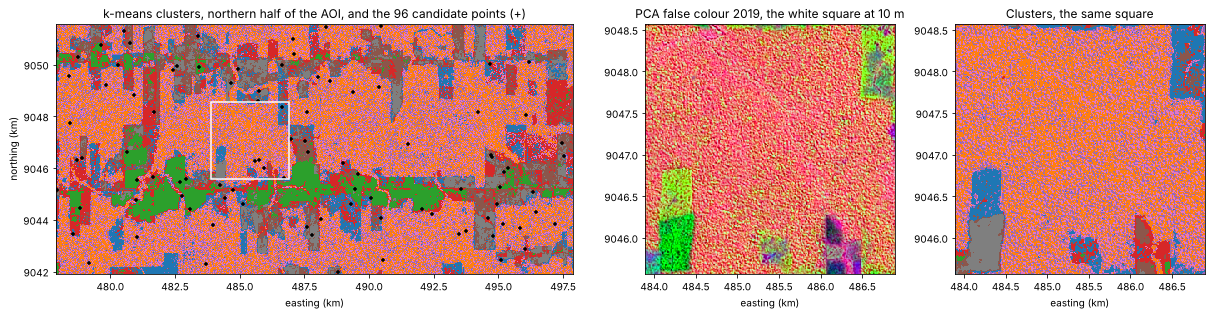

cluster,0,1,2,3,4,5,6,7
forest 2019 (app),,,,,,,,
False,0.93,0.03,1.0,0.99,0.09,0.99,0.09,1.0
True,0.07,0.97,0.0,0.01,0.91,0.01,0.91,0.0


In [20]:
wa = wins[YEAR_A]
ok = wa.valid & half_mask
basis = metrics.fit_pca(wa, ok, sample=100_000, seed=0)
rng = np.random.default_rng(0)
rr, cc = np.nonzero(ok)
take = rng.choice(rr.size, size=100_000, replace=False)
rr, cc = rr[take], cc[take]
vectors = wa.embeddings[rr, cc].astype(np.float32) * wa.scales[rr, cc][:, None]
proj = (vectors - basis.mean) @ basis.components.T
kmeans = KMeans(n_clusters=8, n_init=4, random_state=0).fit(proj)
per_cluster = 12
chosen = np.concatenate([rng.choice(np.flatnonzero(kmeans.labels_ == k), per_cluster, replace=False) for k in range(8)])
rows_g = rr[chosen] + wa.rows.start
cols_g = cc[chosen] + wa.cols.start
x_utm = grid.left + (cols_g + 0.5) * grid.pixel
y_utm = grid.top - (rows_g + 0.5) * grid.pixel
lon, lat = to_lonlat.transform(x_utm, y_utm)
template = pd.DataFrame(
    {
        "lon": lon,
        "lat": lat,
        "label": pd.array([pd.NA] * chosen.size, dtype="Int64"),
        "cluster": kmeans.labels_[chosen],
        "year": YEAR_A,
    }
)
CANDIDATES = Path("out/deforest_candidates.csv")
template.to_csv(CANDIDATES, index=False, float_format="%.7f")
print(f"{CANDIDATES}: {len(template)} points, {per_cluster} per cluster")
print(CANDIDATES.read_text(encoding="utf-8")[:200], "...")


def clusters_of(rows: slice, cols: slice, step: int) -> tuple[np.ndarray, np.ndarray]:
    """Cluster map and PCA false colour of part of the half window, every ``step``-th pixel."""
    sub = wa.embeddings[rows, cols][::step, ::step].astype(np.float32) * wa.scales[rows, cols][::step, ::step, None]
    sub_ok = ok[rows, cols][::step, ::step]
    out = np.full(sub_ok.shape, np.nan)
    out[sub_ok] = kmeans.predict((sub[sub_ok] - basis.mean) @ basis.components.T)
    return out, metrics.pca_rgb(sub, basis, mask=sub_ok)


def km_extent(rows: slice, cols: slice) -> tuple[float, float, float, float]:
    """Plotting extent, in km, of half-window rows and columns."""
    c0, c1 = wa.cols.start + (cols.start or 0), wa.cols.start + (cols.stop or wa.shape[1])
    r0, r1 = wa.rows.start + (rows.start or 0), wa.rows.start + (rows.stop or wa.shape[0])
    left, top = grid.left / 1000, grid.top / 1000
    return (
        left + c0 * grid.pixel / 1000,
        left + c1 * grid.pixel / 1000,
        top - r1 * grid.pixel / 1000,
        top - r0 * grid.pixel / 1000,
    )


everything, crop = (slice(None), slice(None)), (slice(300, 600), slice(600, 900))  # crop: 3 km x 3 km
cluster_map, _ = clusters_of(*everything, STEP)
crop_clusters, crop_rgb = clusters_of(*crop, 1)
cluster_cmap = plt.get_cmap("tab10").with_extremes(bad=GREY)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), layout="constrained", gridspec_kw={"width_ratios": [2.1, 1, 1]})
axes[0].imshow(
    np.ma.masked_invalid(cluster_map),
    cmap=cluster_cmap,
    vmin=0,
    vmax=9,
    extent=km_extent(*everything),
    interpolation="nearest",
)
axes[0].scatter(x_utm / 1000, y_utm / 1000, s=16, c="black", marker="+")
x0, x1, y0, y1 = km_extent(*crop)
axes[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="white", linewidth=1.5))
axes[0].set_title("k-means clusters, northern half of the AOI, and the 96 candidate points (+)")
axes[1].imshow(crop_rgb, extent=km_extent(*crop), interpolation="nearest")
axes[1].set_title(f"PCA false colour {YEAR_A}, the white square at 10 m")
axes[2].imshow(
    np.ma.masked_invalid(crop_clusters),
    cmap=cluster_cmap,
    vmin=0,
    vmax=9,
    extent=km_extent(*crop),
    interpolation="nearest",
)
axes[2].set_title("Clusters, the same square")
for ax in axes:
    ax.set_xlabel("easting (km)")
axes[0].set_ylabel("northing (km)")
plt.show()
share = pd.crosstab(kmeans.labels_, pd.Series(forest_a[r][rr, cc], name="forest 2019 (app)"), normalize="index")
share.index.name = "cluster"
share.round(2).T

The clusters split forest from non-forest almost cleanly, without any label: three are at least 91% forest in
the app's 2019 map and five at least 93% non-forest. The three forest clusters are not three kinds of forest:
they alternate pixel by pixel (the 10 m texture of the canopy, in the 3 km square), while the non-forest clusters
form coherent patches, different kinds of cleared land. Sampling every cluster equally puts 60 of the 96 points on
non-forest of five kinds and 36 on forest, rather than following the most common cover; add the rarer cases that
matter for conversion by hand. The template is meant to be filled in and passed with
`--labels`. Until then the app refuses it, before it opens the store:

In [21]:
try:
    deforest.read_labels_csv(CANDIDATES)
except AppInputError as exc:
    print("Refused:", exc)

Refused: Labels file out/deforest_candidates.csv: label must be 1 (forest) or 0 (non-forest); line(s) 2, 3, 4, 5, 6 and 91 more hold nan.


## 10. Cost

Every run logs the chunk payload bytes it read from the store and its wall time, and records both in the report.
When the call in section 2 was skipped, these are the figures of the run that wrote the outputs.

In [22]:
timings = dict(report["timings"])
wall = timings.pop("wall_s")
gb = report["bytes_read"] / 1e9
print(f"bytes read: {gb:.2f} GB ({report['bytes_read_note']})")
print(f"estimated before the run (upper bound): {report['estimated_bytes'] / 1e9:.2f} GB")
print(f"wall time: {wall:.0f} s, {gb * 1e3 / wall:.0f} MB/s")
print("stages (s):", {k: round(t, 1) for k, t in sorted(timings.items(), key=lambda kv: -kv[1])})
print(f"estimated peak memory: {report['estimated_memory'] / 1e9:.2f} GB")
print("store snapshot:", report["provenance"]["store"]["snapshot_id"], "| years read:", report["provenance"]["years"])
print(f"this notebook's own reads (section 9.2: the label points and half the AOI): {reader.bytes_read / 1e9:.2f} GB")
print(f"the --labels run of section 9.1 read {csv_result.report['bytes_read'] / 1e9:.2f} GB")

bytes read: 1.55 GB (Chunk payload bytes returned by the zarr store (io.CountingStore), gap bytes of merged range requests included. Icechunk manifest and snapshot fetches below the zarr interface are not counted.)
estimated before the run (upper bound): 2.39 GB
wall time: 89 s, 17 MB/s
stages (s): {'stream': 34.7, 'write': 6.2, 'regime_probe': 4.2, 'labels_read': 3.1, 'transfer': 2.7, 'classifier': 0.7, 'clean': 0.2, 'validation': 0.2}
estimated peak memory: 1.51 GB
store snapshot: B6AFRJGX5XQC0A716PA0 | years read: [2019, 2022]
this notebook's own reads (section 9.2: the label points and half the AOI): 0.77 GB
the --labels run of section 9.1 read 1.33 GB


The default run read 1.55 GB in 79 s inside the app; the CLI process took 80.4 s end to end and peaked at
1.86 GB resident memory (1,812,092 KiB, measured with `/usr/bin/time -v`), against the app's own estimate of
1.51 GB, about a fifth low on this AOI. The stream over the AOI's 8 blocks took 18 s. About 40 s went to the preflight before any
chunk read, most of it reading Hansen's layers for the label ring and for the AOI through `/vsicurl/` (from the
log's timestamps). A rerun with the same arguments is skipped in under 3 s. The COG is 57 MB, four float32 bands with overviews.

## 11. Take-aways

- One command maps forest in both years and the conversion between them. On the Rondonia front: 60.6% forest in
  2019, 44.1% in 2022, and 6,018 ha converted, a quarter of the 2019 forest, in 248 patches, most of the area in
  20 patches over 100 ha. It read 1.55 GB in 80 s.
- **Against Hansen loss 2020 to 2022: precision 0.976, recall 0.668, IoU 0.657, F1 0.793.** Against Hansen loss in
  2022 alone, the brief's checkpoint: precision 0.351 (by construction, since 2020 and 2021 conversions count
  against it) and recall 0.731. Nothing was tuned to these numbers.
- The app rarely calls anything converted that Hansen does not. What it misses lies mostly along Hansen's edges
  (53% of the misses are within 30 m of one; recall is 0.79 away from them), in clearings that still read as
  forest in 2022, below the cross-check cut, in pixels the cleaning removes, and in small Hansen patches.
- The survey N13 cross-check cut is the weakest step on a busy front: here it costs 10 points of recall for 1.8 of
  precision, and with few labels it makes recall swing between draws. The app warns when it can (Hansen labels);
  with `--labels` it cannot. Setting the cut from stable land outside the AOI is the change to test next.
- Where no forest layer exists, a few dozen labels per class map forest well. Label fresh clearings explicitly,
  and treat a conversion map from few labels as a lower bound until it has been checked.